# Análisis reproducible de DEAM

## Resultados utilizados en la presentación del recomendador musical emocional

Este notebook reproduce los indicadores descriptivos de la presentación a partir de `DEAM_Annotations.zip`. El análisis cubre inventario, cuadrantes de valencia-activación, subjetividad entre evaluadores y consistencia entre anotaciones estáticas y dinámicas.

El ZIP original está incluido en este mismo paquete. No es necesario extraerlo manualmente.

## 1. Configuración y carga de funciones

In [1]:
from pathlib import Path
import sys
import pandas as pd
from IPython.display import display, Image

PACKAGE_ROOT = Path.cwd()
if not (PACKAGE_ROOT / "DEAM_Annotations.zip").exists():
    # Permite ejecutar el notebook desde Jupyter abierto en otra carpeta.
    PACKAGE_ROOT = Path(".").resolve()

sys.path.insert(0, str(PACKAGE_ROOT / "src"))
from analisis_deam import load_deam, compute_analysis, validate_results

ZIP_PATH = PACKAGE_ROOT / "DEAM_Annotations.zip"
OUTPUT_DIR = PACKAGE_ROOT / "outputs"
print(f"Fuente: {ZIP_PATH.resolve()}")

Fuente: C:\Users\Usuario\Documents\MCD_recomendador_musical_prt\DEAM_Annotations.zip


## 2. Ejecución y validación

In [2]:
data = load_deam(ZIP_PATH)
analysis = compute_analysis(data)
validate_results(analysis)

metrics = analysis["metrics"]
print("Validación completada")
print(f"Canciones: {metrics['songs']:,}")
print(f"Valoraciones individuales: {metrics['individual_ratings']:,}")
print(f"Evaluadores únicos: {metrics['unique_raters']:,}")
print(f"Archivos CSV: {metrics['csv_files']:,}")
print(f"Frecuencia dinámica: {metrics['sampling_frequency_hz']:.0f} Hz")

Validación completada
Canciones: 1,802
Valoraciones individuales: 17,762
Evaluadores únicos: 195
Archivos CSV: 3,610
Frecuencia dinámica: 2 Hz


## 3. Resumen de los indicadores de la presentación

In [3]:
results = pd.read_csv(OUTPUT_DIR / "resultados_presentacion.csv")
display(results)

,indicador,resultado,unidad
0,Canciones o fragmentos,1802.000000,conteo
1,Valoraciones individuales,17762.000000,conteo
2,Evaluadores únicos,195.000000,conteo
3,Archivos CSV,3610.000000,conteo
4,Mediana de evaluadores por canción,10.000000,conteo
5,Frecuencia dinámica,2.000000,Hz
6,Valencia media,4.904145,escala 1-9
7,Activación media,4.814029,escala 1-9
8,Correlación valencia-activación,0.570026,Pearson r
9,Desviación media entre evaluadores: valencia,1.502364,desviación


### Lectura principal

- Las 1.802 canciones tienen etiquetas emocionales estáticas y dinámicas.
- Las 17.762 valoraciones provienen de 195 evaluadores únicos.
- La anotación dinámica tiene intervalos de 500 ms, equivalentes a 2 Hz.
- El ZIP contiene 3.610 archivos CSV y no incluye audio.

## 4. Distribución por cuadrantes emocionales

,songs,percentage
quadrant,,
Negativa / baja,686,38.068812
Positiva / alta,647,35.904550
Positiva / baja,240,13.318535
Negativa / alta,229,12.708102


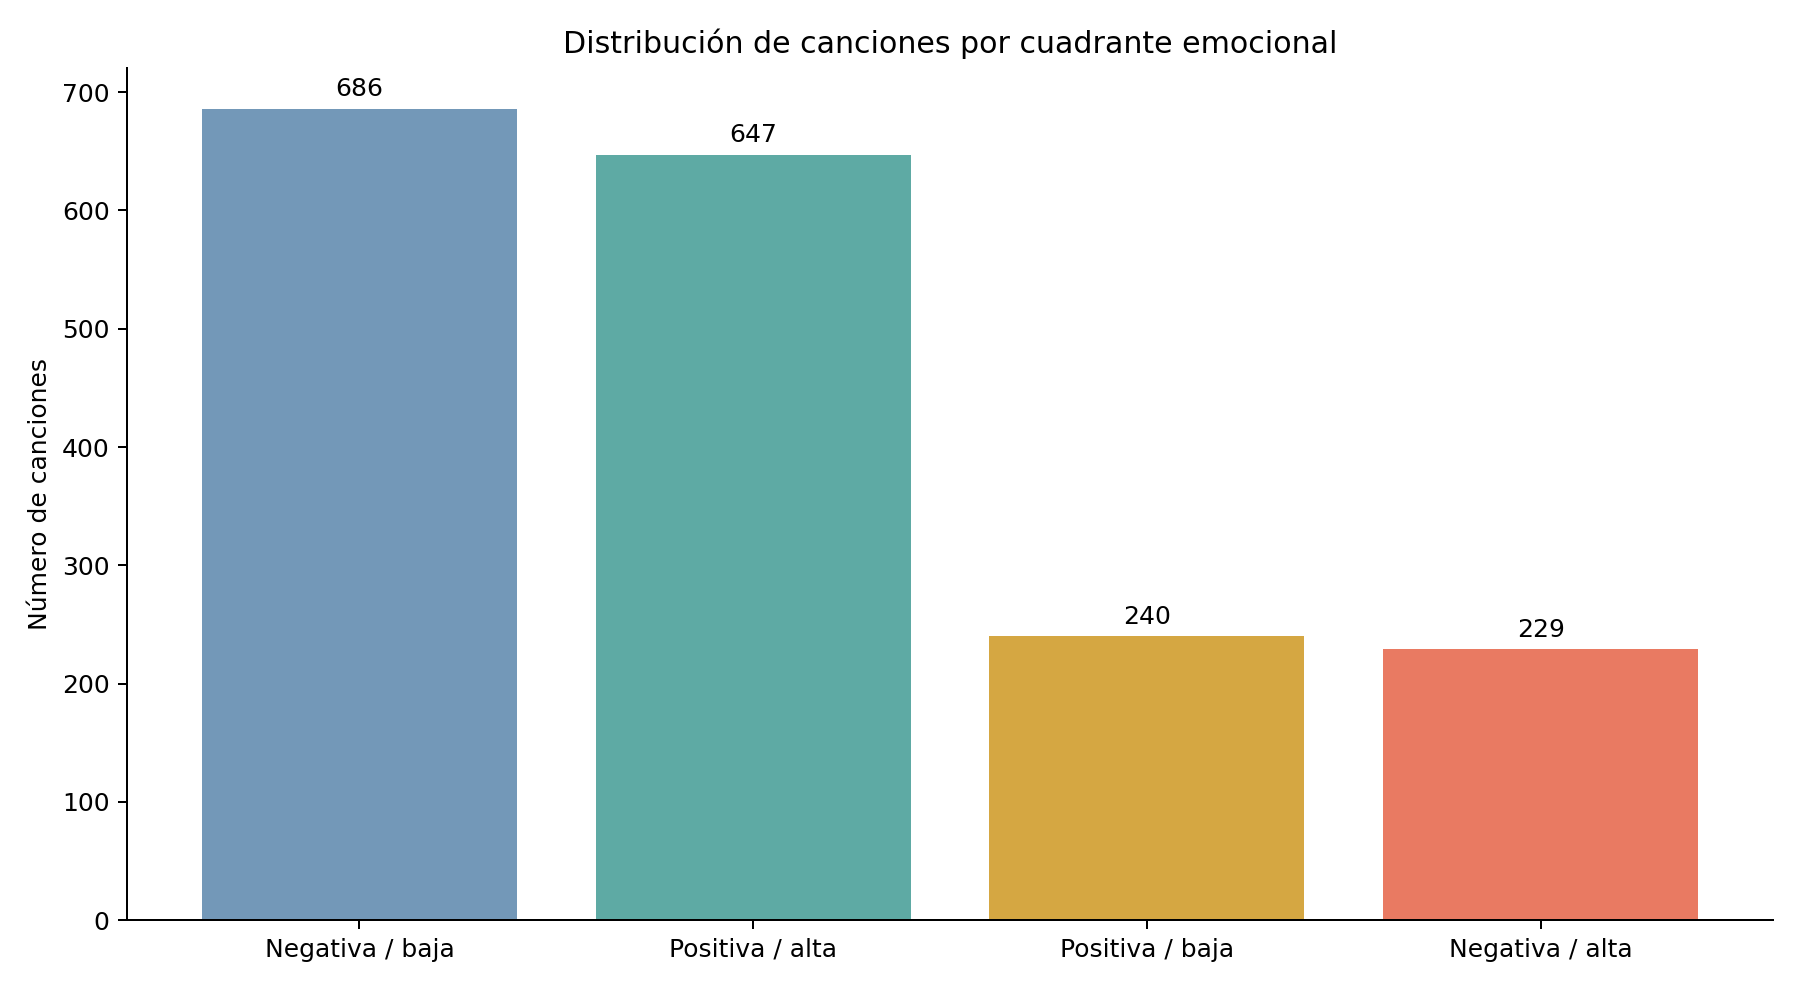

In [4]:
quadrants = analysis["quadrants"]
display(quadrants)
display(Image(filename=str(OUTPUT_DIR / "01_distribucion_cuadrantes.png")))

Los cuadrantes negativa/baja y positiva/alta reúnen aproximadamente el 74 % del catálogo. Por esta razón, la partición de entrenamiento debe conservar la distribución y el desempeño debe reportarse por región emocional.

## 5. Espacio de valencia y activación

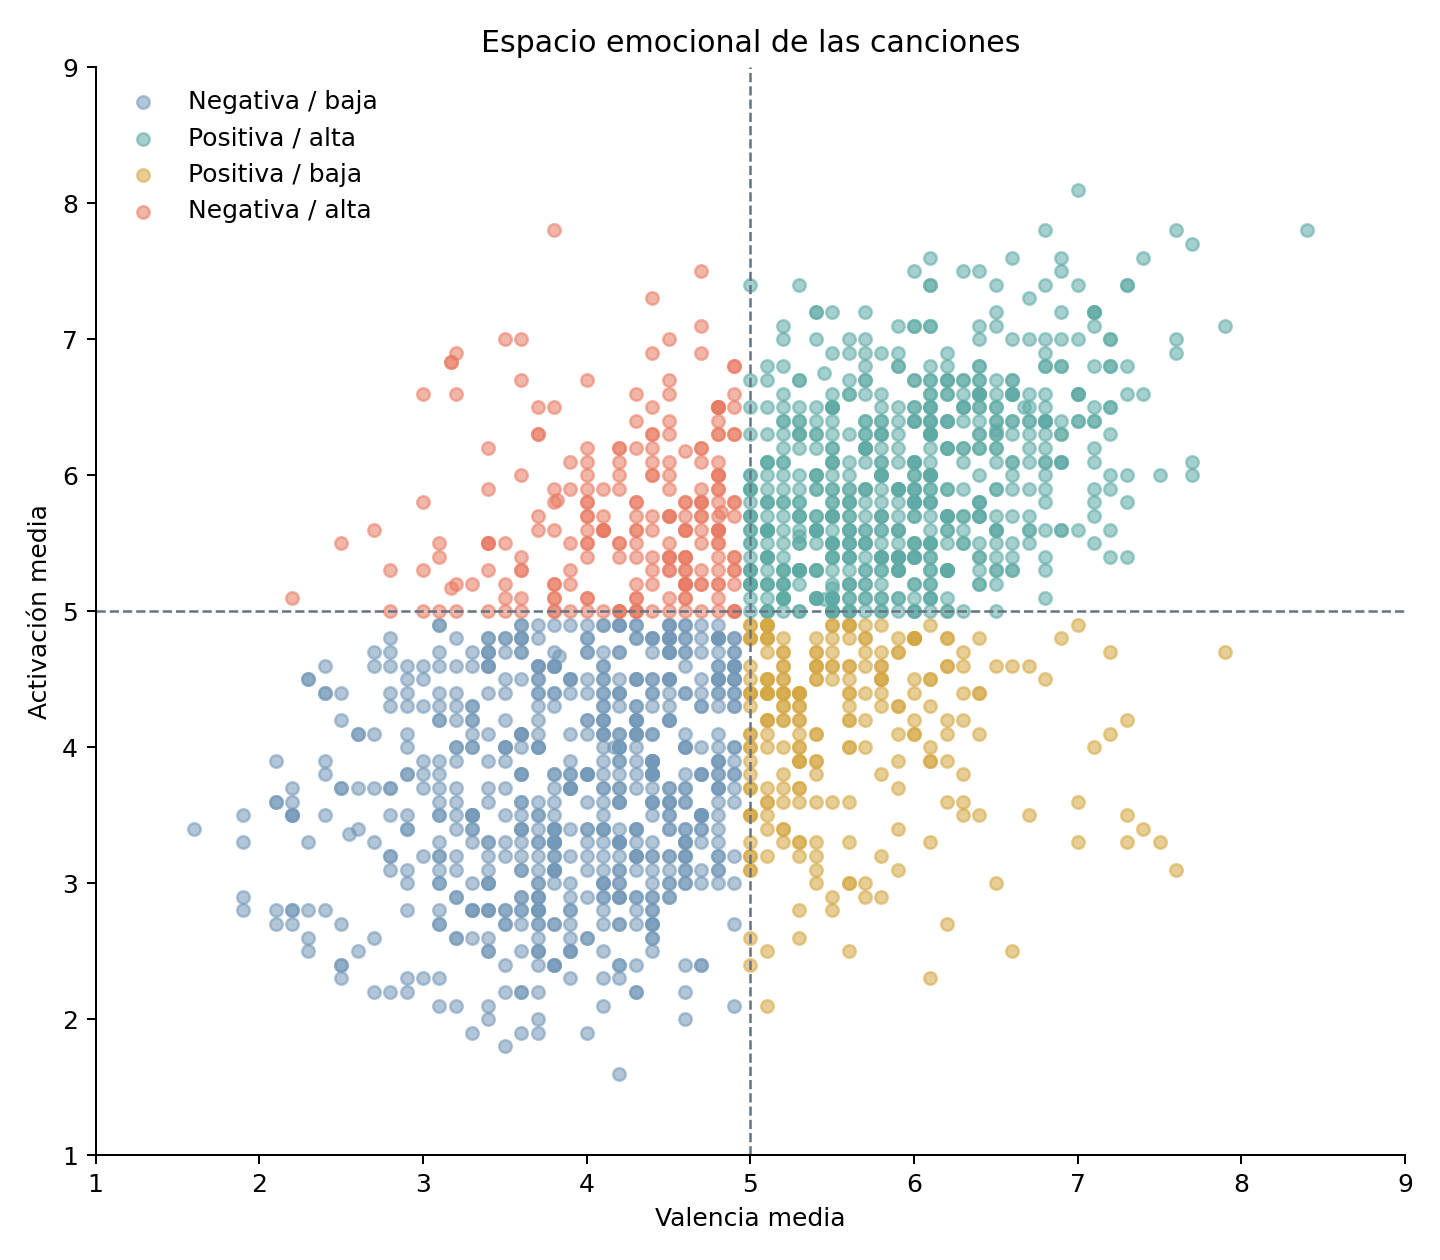

Correlación valencia-activación: 0.570


In [5]:
display(Image(filename=str(OUTPUT_DIR / "02_espacio_valencia_activacion.png")))
print(f"Correlación valencia-activación: {metrics['valence_arousal_correlation']:.3f}")

## 6. Subjetividad emocional

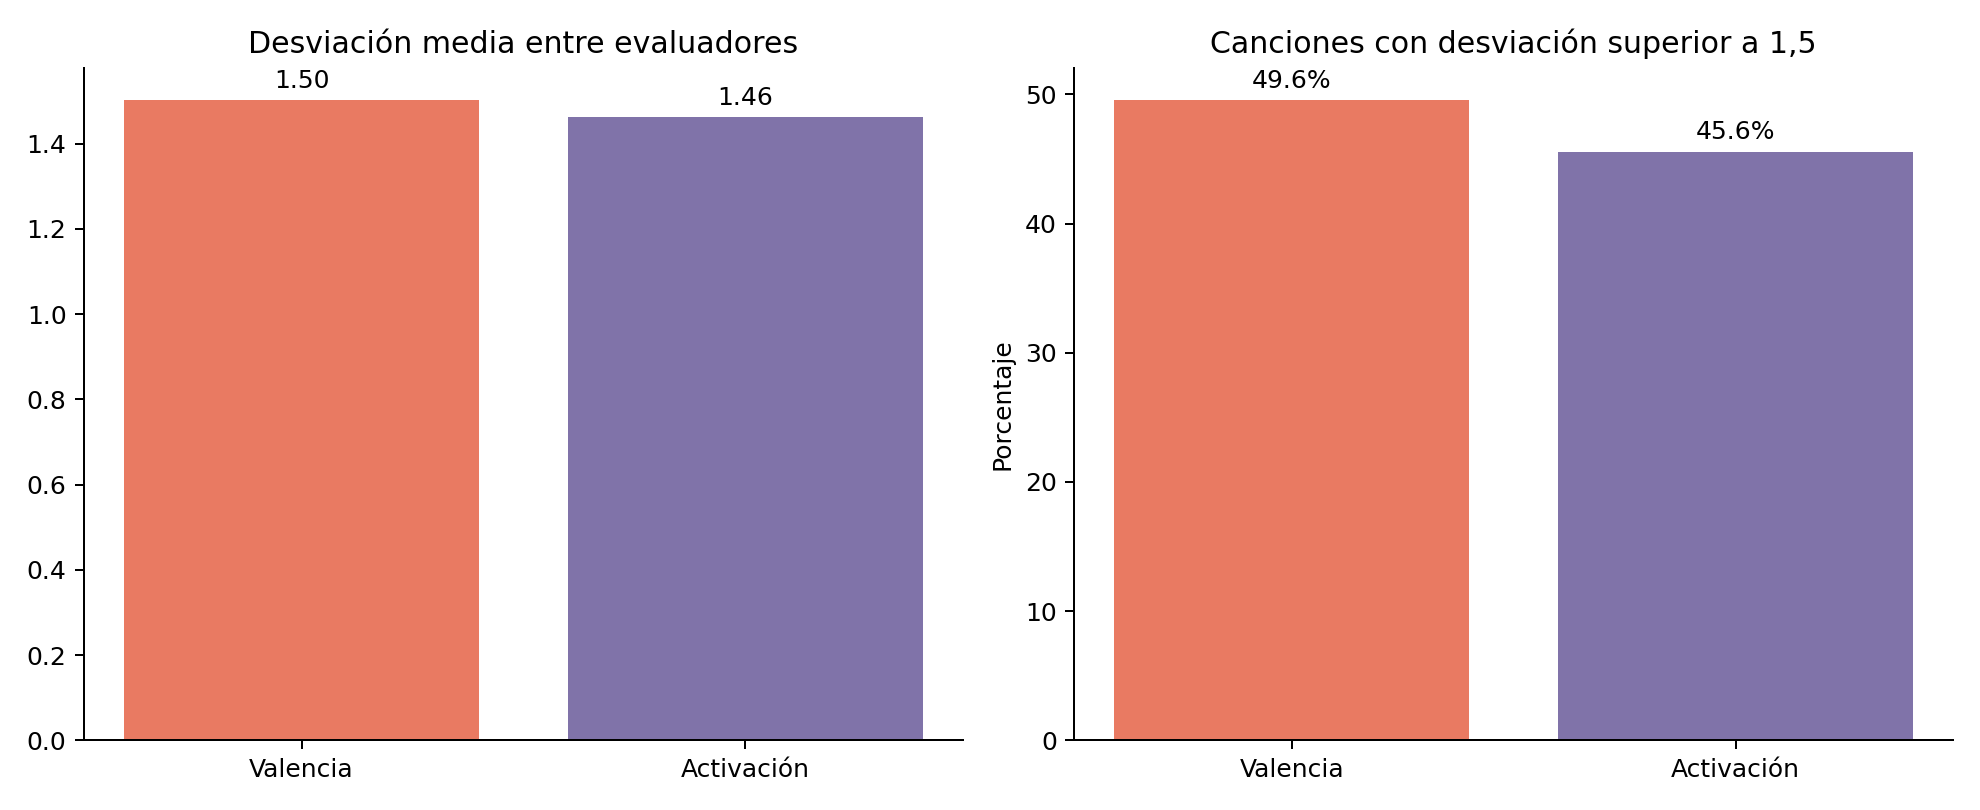

Desviación media de valencia: 1.50
Desviación media de activación: 1.46
Valencia con desviación > 1.5: 49.6%
Activación con desviación > 1.5: 45.6%


In [6]:
display(Image(filename=str(OUTPUT_DIR / "03_subjetividad_emocional.png")))
print(f"Desviación media de valencia: {metrics['mean_interrater_valence_sd']:.2f}")
print(f"Desviación media de activación: {metrics['mean_interrater_arousal_sd']:.2f}")
print(f"Valencia con desviación > 1.5: {metrics['valence_sd_over_1_5_pct']:.1f}%")
print(f"Activación con desviación > 1.5: {metrics['arousal_sd_over_1_5_pct']:.1f}%")

La variación entre evaluadores no se trata únicamente como ruido. Es evidencia de que la percepción musical cambia entre personas y justifica incorporar incertidumbre y personalización.

## 7. Consistencia entre anotaciones estáticas y dinámicas

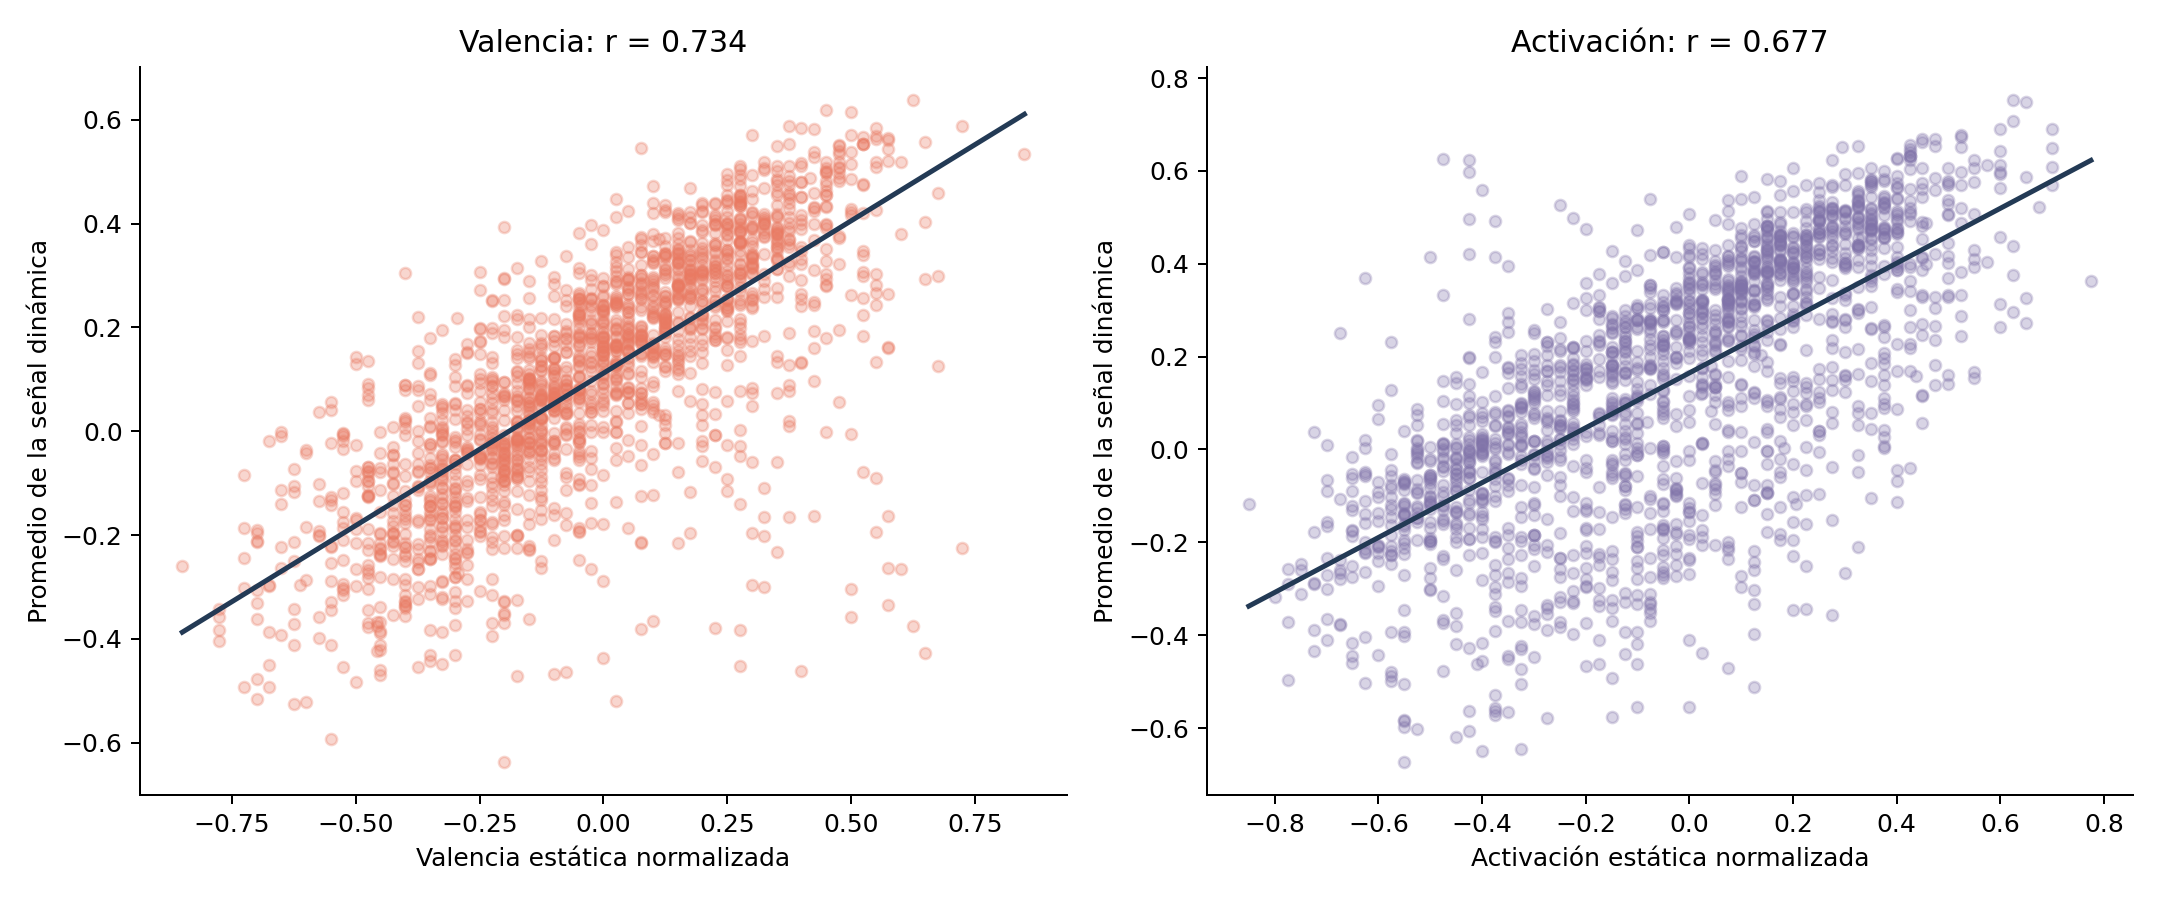

Valencia: r = 0.734
Activación: r = 0.677


In [7]:
display(Image(filename=str(OUTPUT_DIR / "04_consistencia_estatica_dinamica.png")))
print(f"Valencia: r = {metrics['static_dynamic_valence_correlation']:.3f}")
print(f"Activación: r = {metrics['static_dynamic_arousal_correlation']:.3f}")

# Fase I: perfiles de anotación, clasificador y prototipo

Las secciones siguientes cumplen los objetivos específicos 2 a 5 de la propuesta: construir perfiles de anotación, agruparlos, caracterizarlos y clasificarlos. Al final se presenta un **prototipo** de recomendador emocional como vista previa de la Fase II.

## 9. Construcción de perfiles de anotación

In [8]:
from perfiles_recomendador import (
    compute_phase1, validate_phase1, save_phase1_tables, save_phase1_plots,
    recommend_emotion, emotional_route, EMOTIONS, MIN_RATINGS_PER_RATER,
)

phase1 = compute_phase1(analysis)
validate_phase1(phase1)
save_phase1_tables(phase1, OUTPUT_DIR)
save_phase1_plots(phase1, OUTPUT_DIR)

m1 = phase1["metrics"]
profiles = phase1["cluster"]["profiles"]
print(f"Evaluadores con al menos {MIN_RATINGS_PER_RATER} canciones: {m1['evaluadores_con_perfil']} de {m1['evaluadores_totales']}")
display(profiles.head())

Evaluadores con al menos 10 canciones: 116 de 195


,worker_id,n_canciones,valencia_media,activacion_media,valencia_sd,activacion_sd,sesgo_valencia,sesgo_activacion,discrepancia,grupo
0,00de940f0b5cfc82cca4791199e3bfb3,751,4.548602,3.383489,1.564598,1.264677,-0.483503,-1.372392,1.485871,2
1,00fa8d61b5f75e16ea71bff7a3def9c9,30,5.366667,4.733333,1.401559,1.740657,0.251852,-0.266667,1.003704,1
2,0bda2743e12d8a204ab04122658d73a3,18,5.277778,3.222222,1.017815,1.664705,0.172840,-1.382716,1.061728,2
3,0c37993dcf5f99f7b00d02495ed01bc3,334,2.961652,5.286136,1.844953,1.579496,-1.883000,0.259590,1.566870,2
4,0ca907e233b8bf33bf4eca86fcbfcc8f,54,5.111111,5.703704,1.869988,1.849320,0.133745,1.020576,1.103909,1


Cada fila es un **evaluador** (unidad de análisis). Solo se incluyen evaluadores con al menos 10 canciones para que sus estadísticas sean estables. Variables del perfil:

| Variable | Qué mide |
|---|---|
| `valencia_media`, `activacion_media` | Nivel promedio de sus respuestas |
| `valencia_sd`, `activacion_sd` | Cuánto varían sus respuestas |
| `sesgo_valencia`, `sesgo_activacion` | Diferencia media frente al consenso de los demás evaluadores de la misma canción (> 0 = percibe más positivo / más energía) |
| `discrepancia` | Distancia absoluta media al consenso |

El **sesgo** es la variable clave: compara a cada persona contra los demás *en las mismas canciones*, por lo que no depende de qué canciones le tocaron.

## 10. Agrupamiento con K-Means

,k,inercia,silhouette
0,2,617.008733,0.236714
1,3,516.540198,0.219400
2,4,429.263590,0.209641
3,5,371.025597,0.215066
4,6,318.637684,0.217411


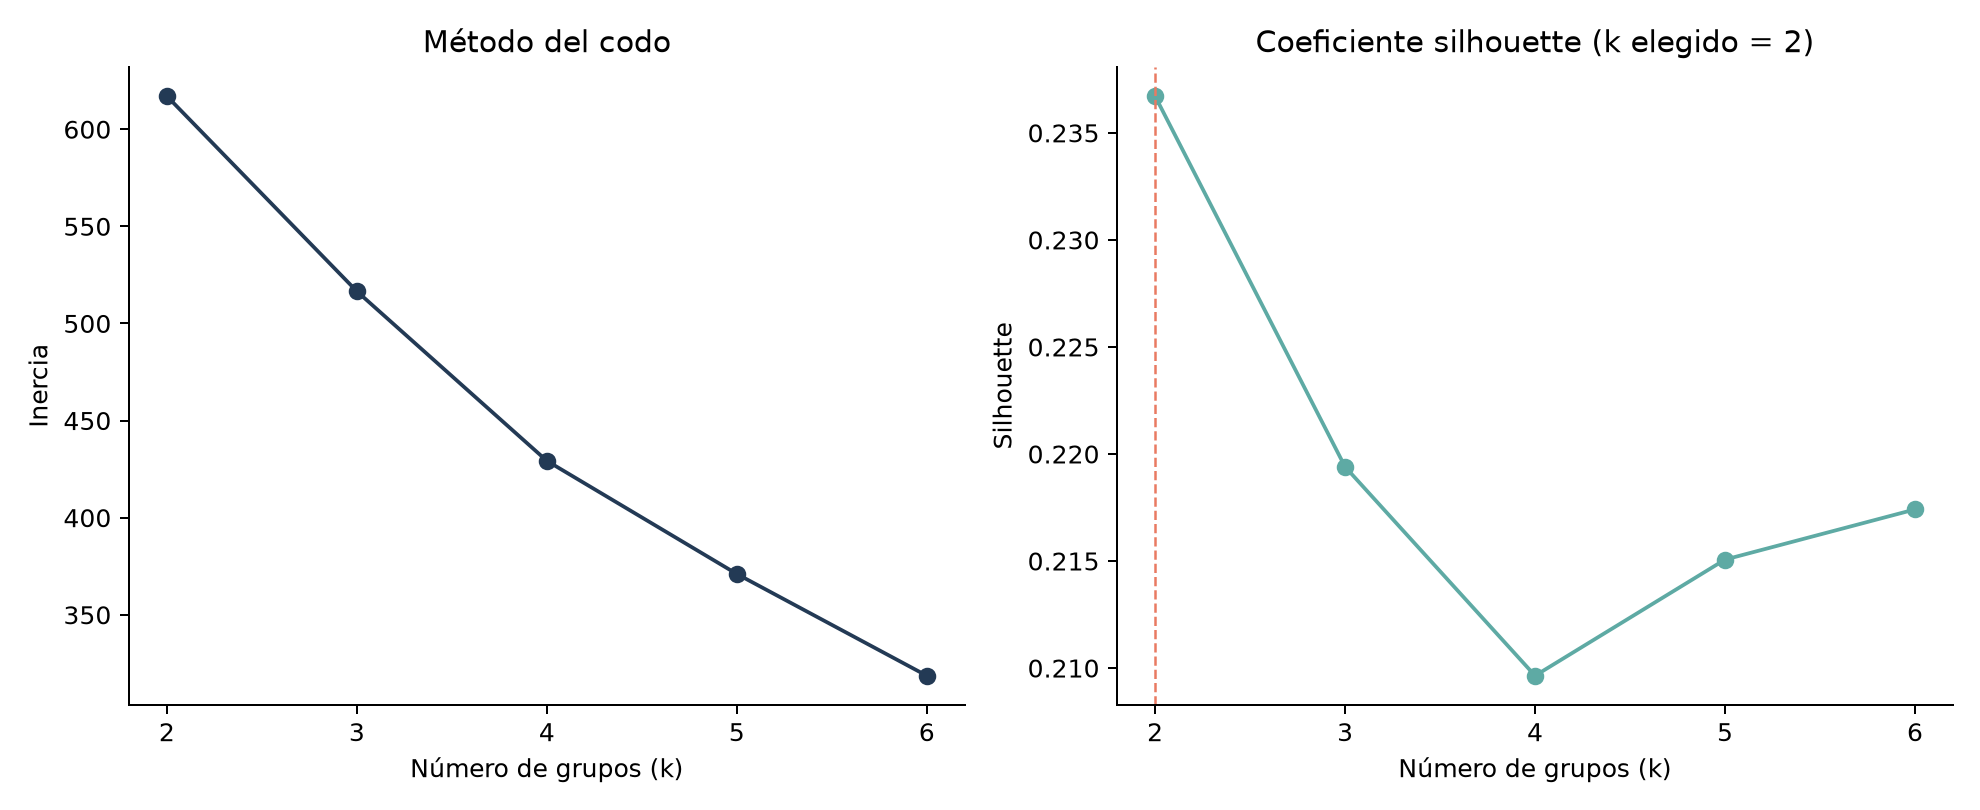

k elegido por silhouette: 2 (silhouette = 0.237)


In [9]:
display(phase1["cluster"]["selection"])
display(Image(filename=str(OUTPUT_DIR / "05_seleccion_numero_grupos.png")))
print(f"k elegido por silhouette: {m1['k_elegido']} (silhouette = {m1['silhouette']:.3f})")

,descripcion,evaluadores,valencia_media,activacion_media,valencia_sd,activacion_sd,sesgo_valencia,sesgo_activacion,discrepancia
grupo,,,,,,,,,
1,"Valencias altas, perciben más positividad",73,5.25,5.32,1.81,1.75,0.34,0.46,1.26
2,"Valencias bajas, perciben más negatividad",43,4.15,4.28,1.74,1.85,-0.70,-0.54,1.32


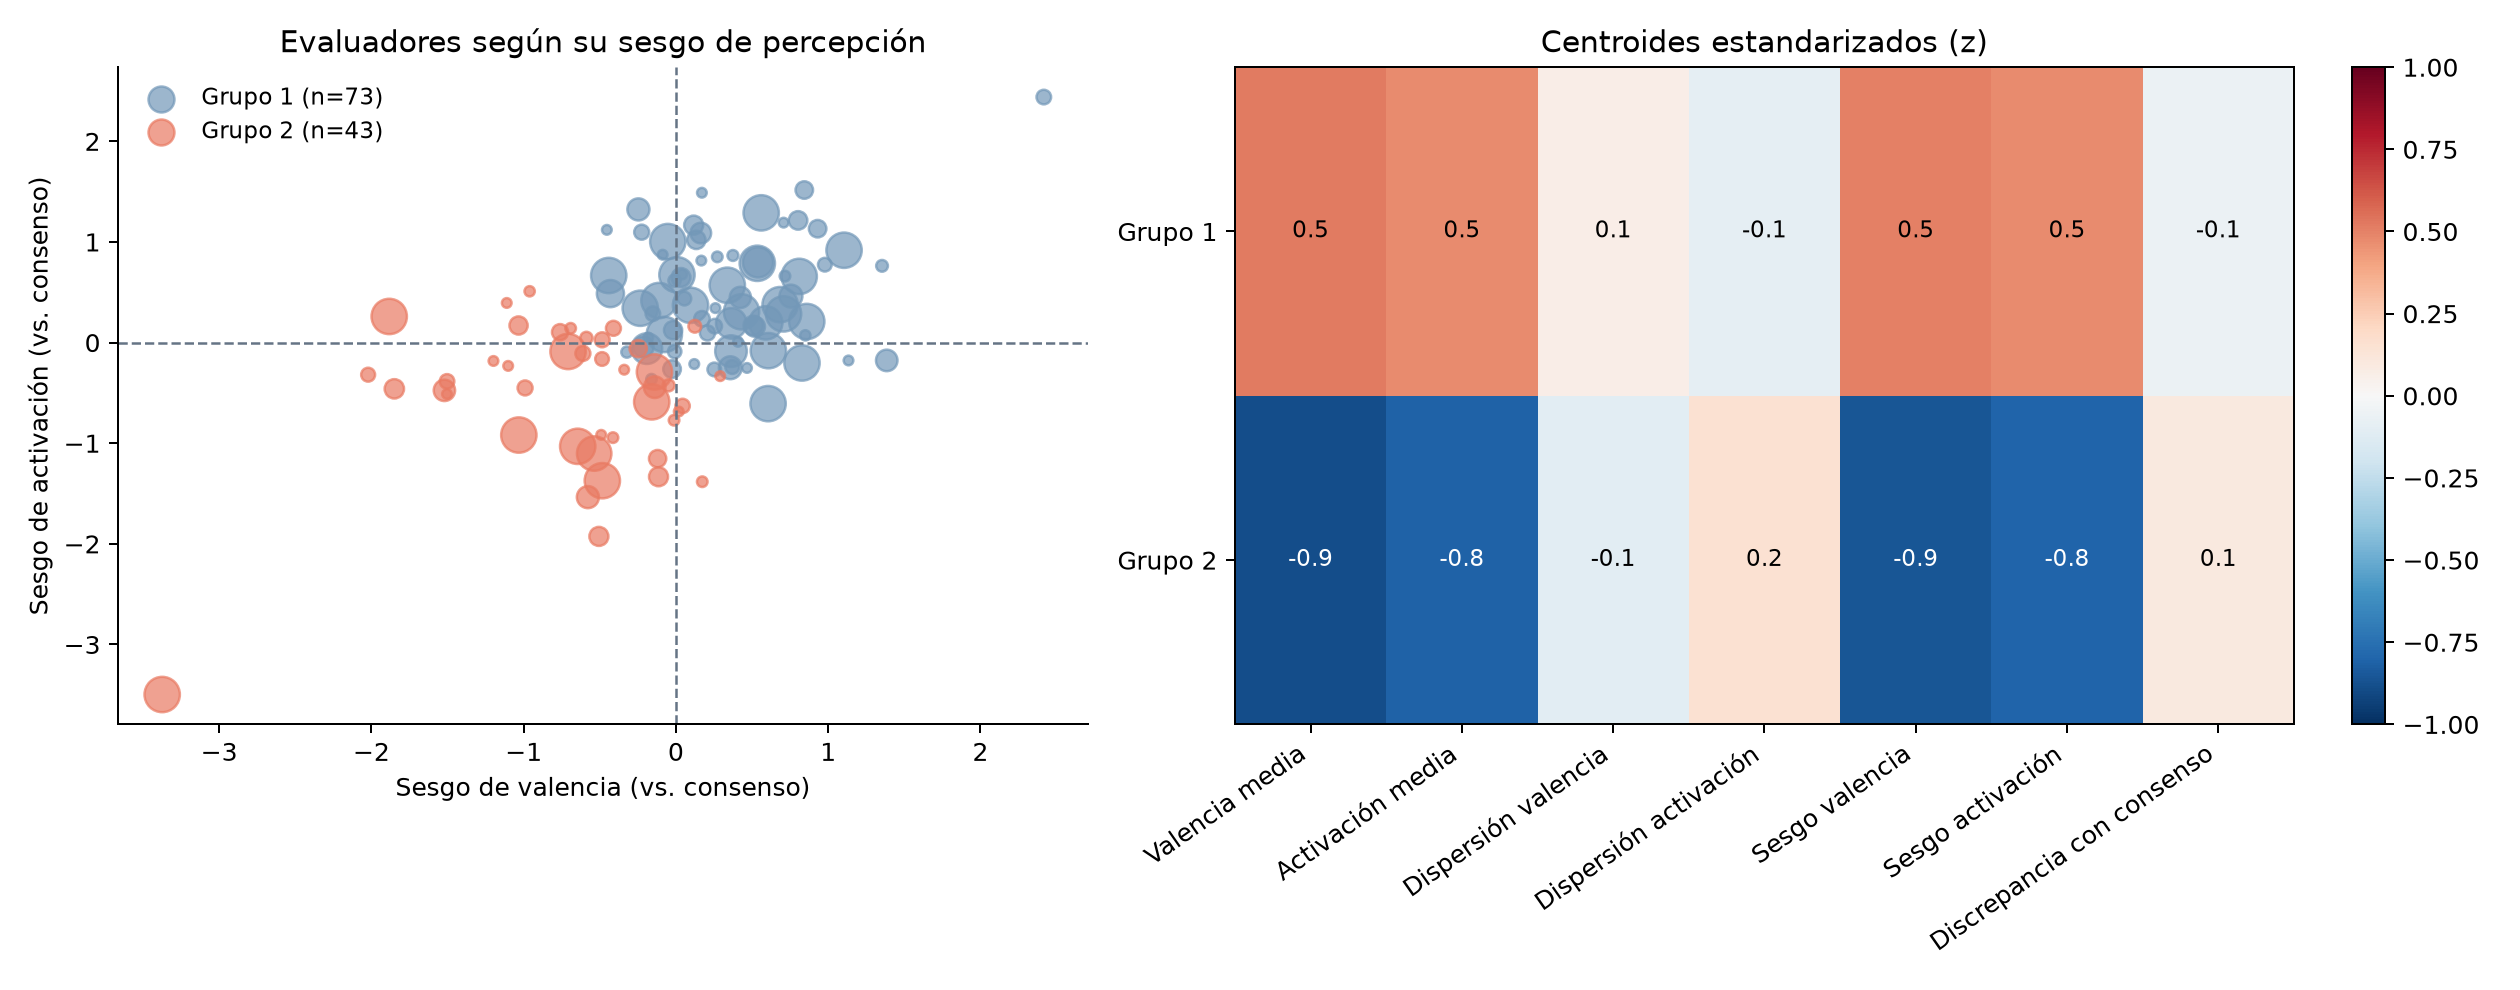

In [10]:
display(phase1["cluster"]["summary"].round(2))
display(Image(filename=str(OUTPUT_DIR / "06_perfiles_anotacion.png")))

**Lectura.** El número de grupos se elige con el coeficiente *silhouette*. Se obtienen dos perfiles de anotación:

- **Grupo 1:** evaluadores que, frente al consenso, perciben la música **más positiva y más enérgica**.
- **Grupo 2:** evaluadores que la perciben **más negativa y con menos energía**.

El silhouette es moderado (~0,24): los grupos son diferenciables pero no están completamente separados; la percepción emocional se distribuye de forma continua. Por ello se habla de *perfiles de anotación* y no de tipos psicológicos de oyentes.

## 11. Clasificador de perfiles

Validación cruzada estratificada de 5 particiones
Accuracy: 89.7%   |   Accuracy balanceada: 88.9%
Línea base (clase mayoritaria): 62.9%


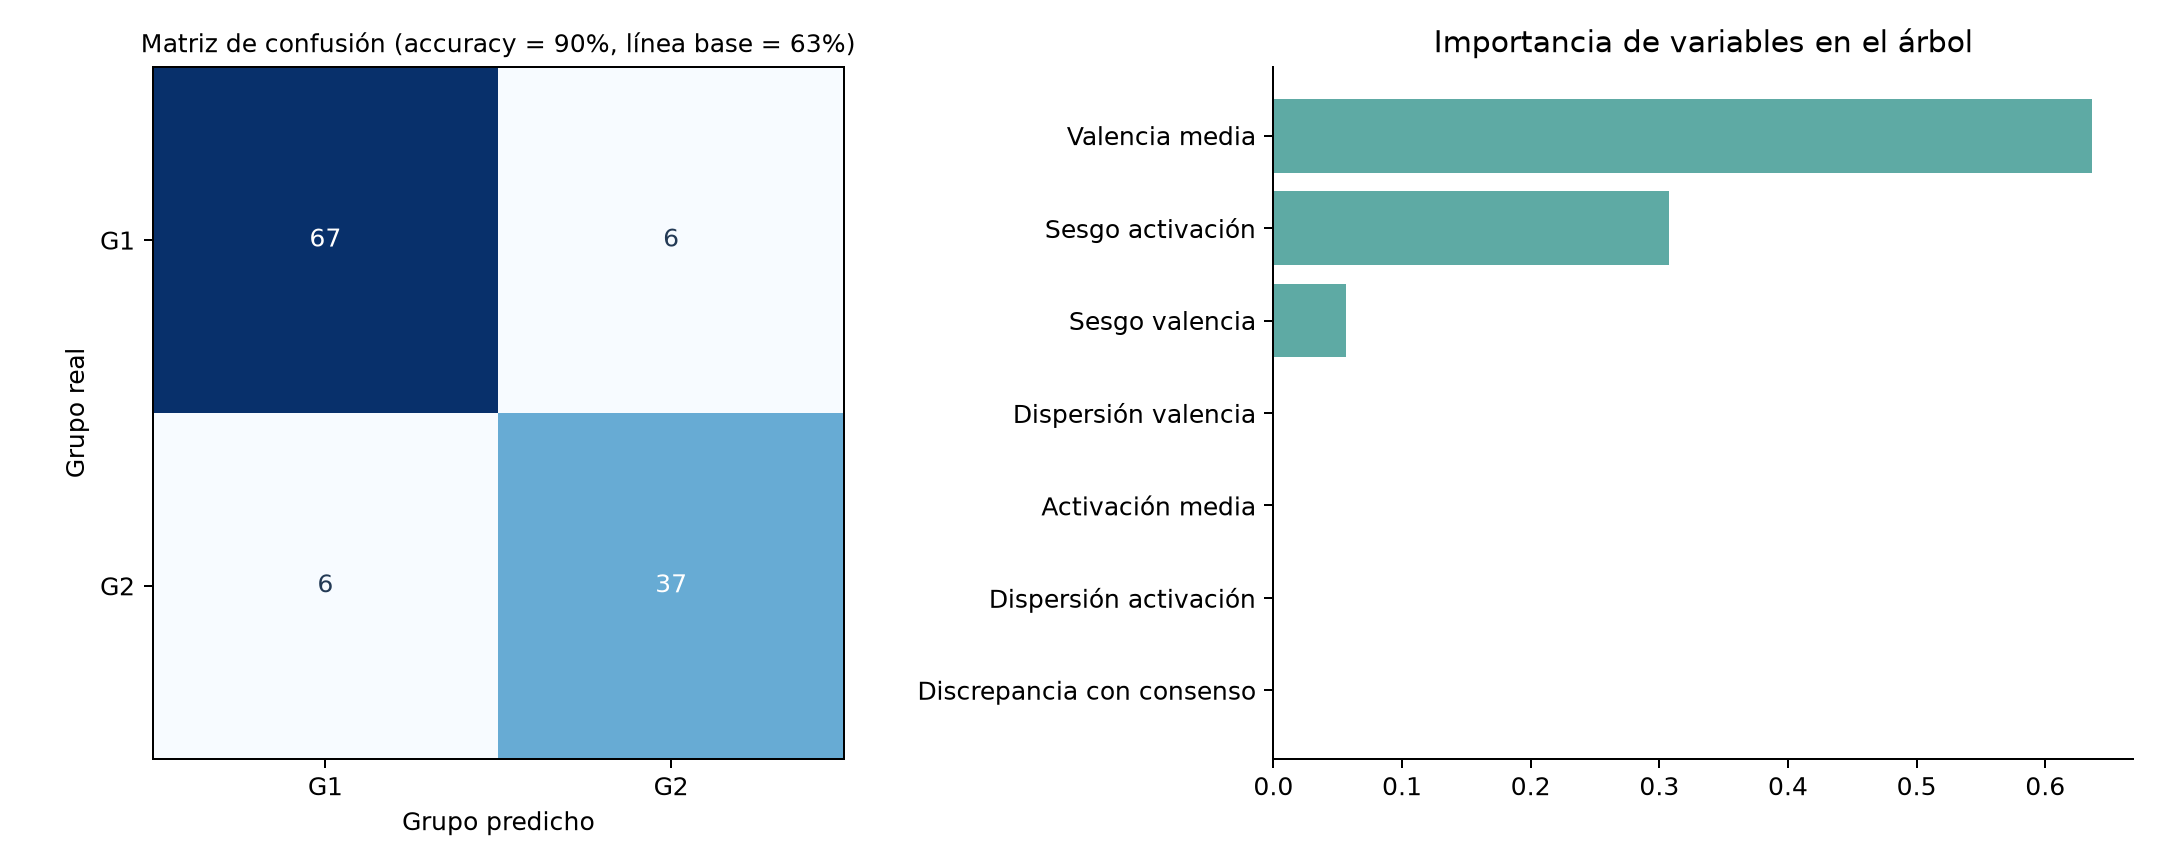

Reglas del árbol de decisión:
|--- valencia_media <= 4.59
|   |--- sesgo_activacion <= 0.44
|   |   |--- sesgo_valencia <= -0.22
|   |   |   |--- class: 2
|   |   |--- sesgo_valencia >  -0.22
|   |   |   |--- class: 2
|   |--- sesgo_activacion >  0.44
|   |   |--- sesgo_valencia <= -0.71
|   |   |   |--- class: 2
|   |   |--- sesgo_valencia >  -0.71
|   |   |   |--- class: 1
|--- valencia_media >  4.59
|   |--- sesgo_activacion <= -0.28
|   |   |--- valencia_media <= 5.31
|   |   |   |--- class: 2
|   |   |--- valencia_media >  5.31
|   |   |   |--- class: 1
|   |--- sesgo_activacion >  -0.28
|   |   |--- sesgo_valencia <= -0.37
|   |   |   |--- class: 1
|   |   |--- sesgo_valencia >  -0.37
|   |   |   |--- class: 1



In [11]:
clf = phase1["classifier"]
print(f"Validación cruzada estratificada de {clf['n_splits']} particiones")
print(f"Accuracy: {clf['accuracy']:.1%}   |   Accuracy balanceada: {clf['balanced_accuracy']:.1%}")
print(f"Línea base (clase mayoritaria): {clf['baseline_accuracy']:.1%}")
display(Image(filename=str(OUTPUT_DIR / "07_clasificador_perfiles.png")))
print("Reglas del árbol de decisión:")
print(clf["rules"])

Un **árbol de decisión** de profundidad 3 asigna nuevos perfiles a su grupo con una precisión muy superior a la línea base. Las reglas son legibles, lo que facilita explicar por qué un evaluador pertenece a un grupo.

*Limitación:* el clasificador aprende grupos definidos con las mismas variables, por lo que su desempeño mide la **reproducibilidad** de los grupos, no la capacidad de predecir un rasgo externo.

## 12. Prototipo de recomendador emocional (vista previa de la Fase II)

El usuario elige una emoción, que se ubica como un punto en el espacio valencia-activación. El sistema ordena las canciones por:

`puntaje = distancia a la emoción + 0,3 × incertidumbre entre evaluadores`

De este modo se prefieren canciones cercanas a la emoción **y** con alto acuerdo entre evaluadores, aprovechando el hallazgo de subjetividad de la sección 6.

Emociones disponibles: alegre, energico, relajado, tranquilo, triste, melancolico, tenso, enojado


,song_id,valencia_percibida,activacion_percibida,quadrant,distancia,incertidumbre,puntaje
0,729,6.4,3.5,Positiva / baja,0.10,1.30,0.49
1,2048,6.2,3.6,Positiva / baja,0.32,1.12,0.65
2,161,6.3,3.5,Positiva / baja,0.20,1.55,0.66
3,987,6.3,3.6,Positiva / baja,0.22,1.59,0.70
4,43,6.7,3.5,Positiva / baja,0.20,1.92,0.77


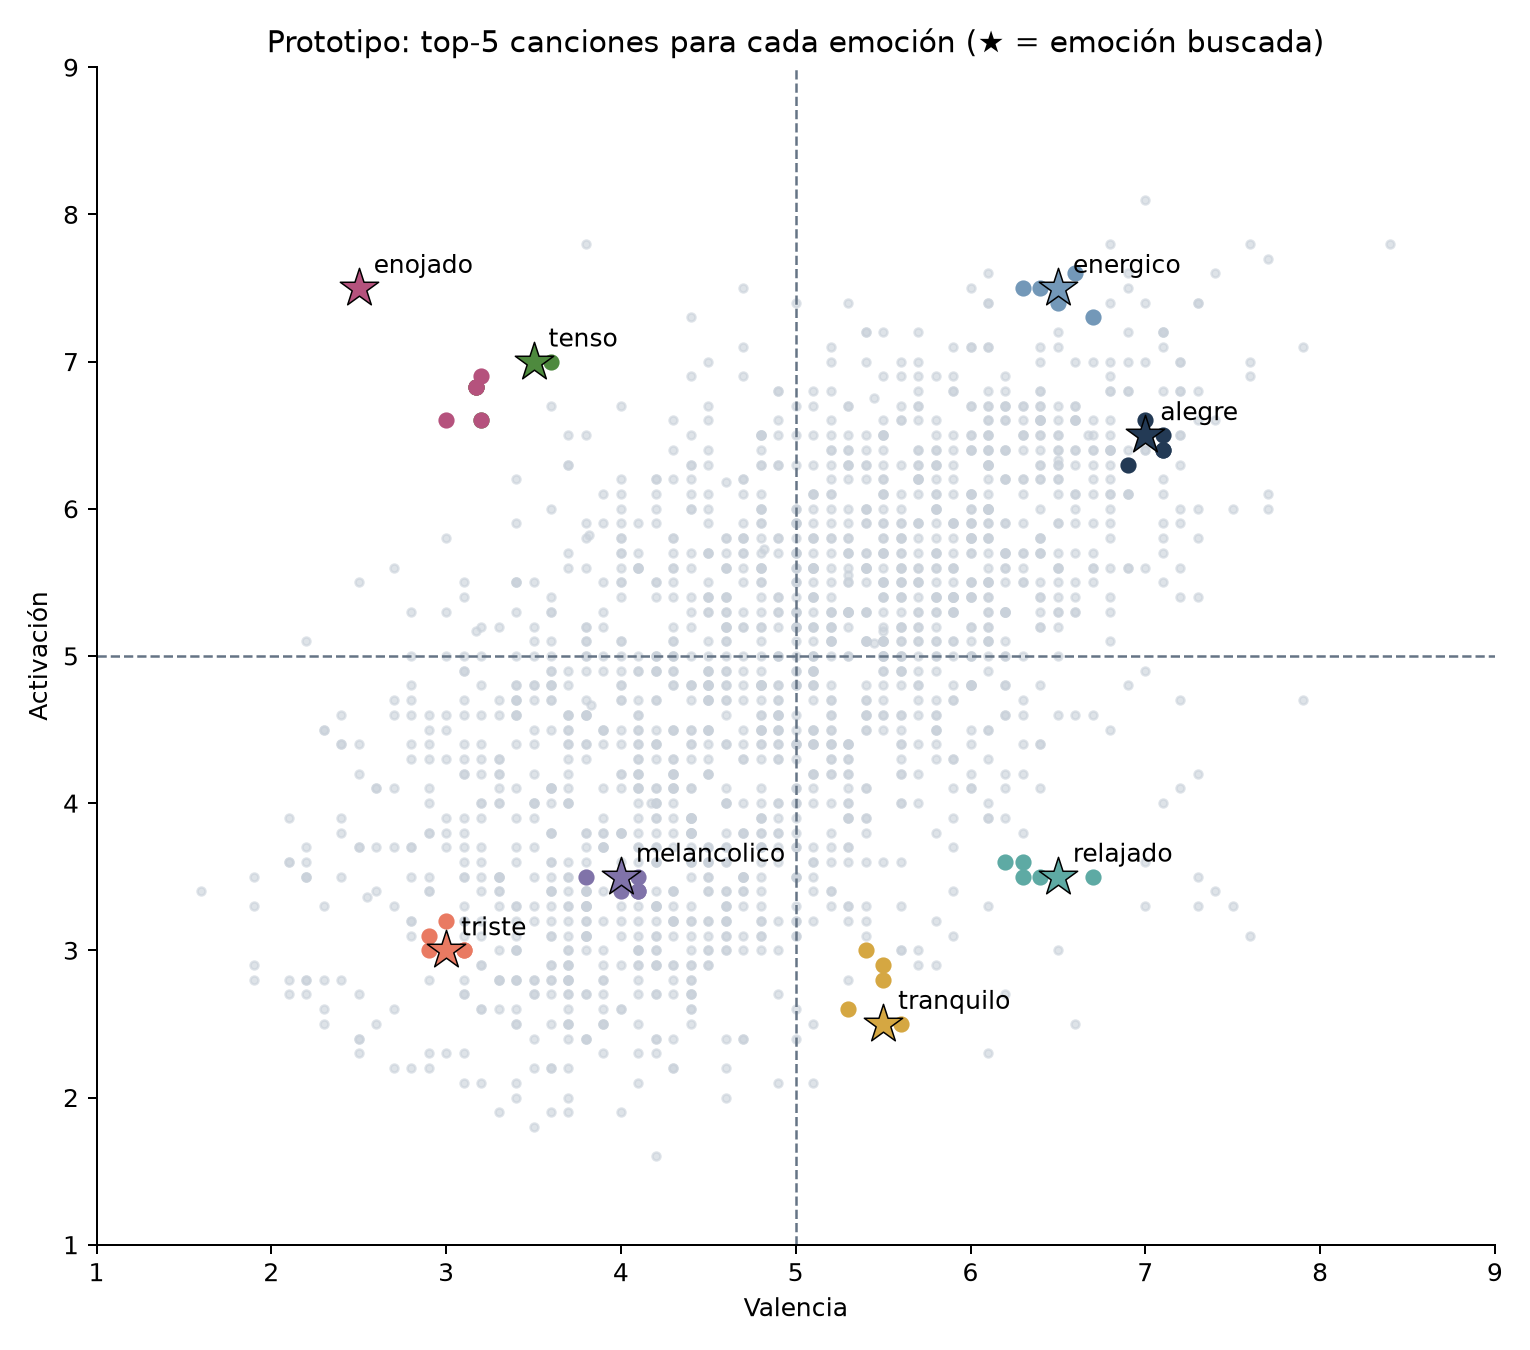

In [12]:
print("Emociones disponibles:", ", ".join(EMOTIONS))
display(recommend_emotion(phase1["catalog"], "relajado").round(2))
display(Image(filename=str(OUTPUT_DIR / "08_recomendaciones_por_emocion.png")))

**Personalización por perfil.** El sesgo medio de cada grupo ajusta cómo se percibe cada canción. La misma petición produce listas distintas según el perfil del oyente:

In [13]:
for group, bias in phase1["biases"].items():
    print(f"Grupo {group}: sesgo valencia = {bias[0]:+.2f}, sesgo activación = {bias[1]:+.2f}")
    display(recommend_emotion(phase1["catalog"], "alegre", bias=bias).round(2))

Grupo 1: sesgo valencia = +0.34, sesgo activación = +0.46


,song_id,valencia_percibida,activacion_percibida,quadrant,distancia,incertidumbre,puntaje
0,1817,6.94,6.46,Positiva / alta,0.07,1.01,0.37
1,2020,7.14,6.26,Positiva / alta,0.28,0.40,0.40
2,1895,6.84,6.36,Positiva / alta,0.21,0.80,0.45
3,759,7.04,6.36,Positiva / alta,0.15,1.02,0.45
4,1078,7.14,6.46,Positiva / alta,0.15,1.18,0.50


Grupo 2: sesgo valencia = -0.70, sesgo activación = -0.54


,song_id,valencia_percibida,activacion_percibida,quadrant,distancia,incertidumbre,puntaje
0,964,6.9,6.46,Positiva / alta,0.11,1.20,0.47
1,1761,7.2,6.56,Positiva / alta,0.21,1.02,0.52
2,257,6.9,6.36,Positiva / alta,0.17,1.60,0.65
3,1471,6.6,6.26,Positiva / alta,0.47,1.08,0.79
4,292,6.6,6.86,Positiva / alta,0.54,0.96,0.83


**Ruta emocional.** Inspirada en el *principio iso* de la musicoterapia: se parte del estado actual del oyente y se avanza gradualmente hacia el estado deseado.

,paso,valencia_objetivo,activacion_objetivo,song_id,valencia_percibida,activacion_percibida,quadrant,distancia,incertidumbre,puntaje
0,1,3.0,3.0,2,3.1,3.0,Negativa / baja,0.1,0.78,0.34
1,2,3.8,3.7,2053,3.8,3.8,Negativa / baja,0.1,1.12,0.43
2,3,4.6,4.4,741,4.6,4.4,Negativa / baja,0.0,1.50,0.45
3,4,5.4,5.1,1005,5.4,5.1,Positiva / alta,0.0,1.25,0.38
4,5,6.2,5.8,1824,6.2,5.7,Positiva / alta,0.1,0.88,0.36
5,6,7.0,6.5,944,7.1,6.5,Positiva / alta,0.1,1.07,0.42


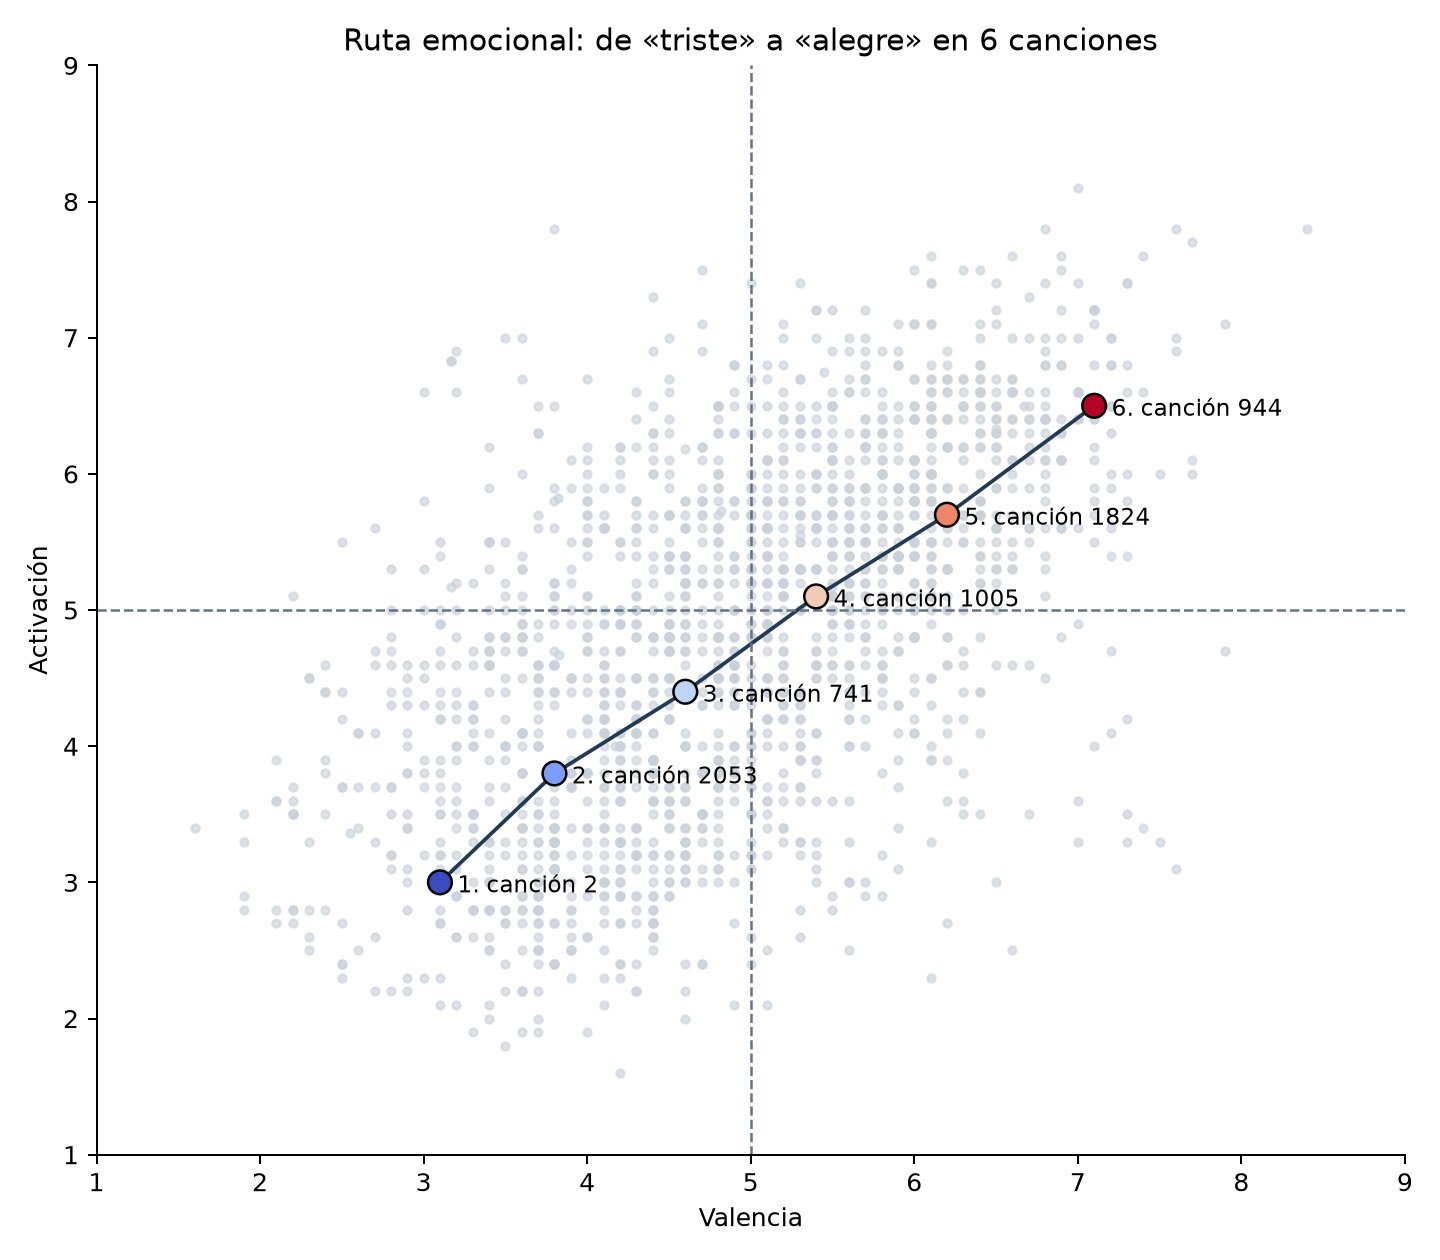

In [14]:
display(phase1["route"].round(2))
display(Image(filename=str(OUTPUT_DIR / "09_ruta_emocional.png")))

**Hallazgo del prototipo.** El catálogo DEAM tiene pocas canciones en la zona *negativa / alta* (enojo, tensión): las recomendaciones para «enojado» quedan más lejos del punto buscado. Esto confirma el desbalance de cuadrantes de la sección 4 y señala la necesidad de ampliar el catálogo en fases posteriores.

## 13. Conclusión y próximos pasos

**Fase I cumplida:**

1. Se construyeron perfiles de anotación para 116 evaluadores a partir de valencia, activación, dispersión y sesgo frente al consenso.
2. K-Means identificó dos perfiles: oyentes que perciben la música más positiva/enérgica y oyentes que la perciben más negativa/calmada.
3. Un árbol de decisión reproduce los grupos con una precisión cercana al 90 % (línea base ≈ 63 %).
4. Un prototipo demuestra cómo usar el espacio emocional, la incertidumbre y el perfil del oyente para recomendar.

**Próximos pasos (Fase II):**

- **Predicción desde el audio:** usar las características acústicas de DEAM (`features.zip`) o transfer learning sobre el audio para estimar valencia y activación de canciones nuevas.
- **Modelo híbrido personalizado:** requiere interacciones usuario-canción recolectadas mediante un piloto.
- **Evaluación:** relevancia, diversidad y satisfacción del usuario.
